# Araç Yakıt Tüketimi Tahmini — Uçtan Uca ML Pipeline Ödevi

**Problem:** Bir aracın **birleşik yakıt tüketimini (L/100 km)** teknik özelliklerinden tahmin etmek → **Regresyon**

**Veri seti (Kanada Hükümeti – Fuel Consumption Ratings):**
- Kaggle (derlenmiş, 7.385 satır, önerilen): https://www.kaggle.com/datasets/debajyotipodder/co2-emission-by-vehicles
- Kaggle (alternatif kopya): https://www.kaggle.com/datasets/isaacfemiogunniyi/co2-emission-of-vehicles-in-canada
- Resmi kaynak (Open Canada, yıllara göre CSV): https://open.canada.ca/data/en/dataset/98f1a129-f628-4ce4-b24d-6f16bf24dd64

**Çalıştırma:** Kaggle'dan indirdiğiniz CSV'yi (`CO2 Emissions_Canada.csv`) bu notebook ile **aynı klasöre** koyun (Colab'de sol panelden yükleyin) ve hücreleri sırayla çalıştırın.

| Adım | İçerik |
|---|---|
| 1-2 | Dataset ve problem türü |
| 3-4 | Veri tanımlama, histogram / grafikler |
| 5 | Ön işleme (eksik, çift, aykırı, encoding) |
| 6 | Korelasyon, heatmap, VIF |
| 7 | Feature engineering + feature selection |
| 8 | Train/Val/Test + 12 model + metrikler |
| 9 | Hiperparametre optimizasyonu (Optuna, RandomSearch, GridSearch) |
| 10-11 | Kara kutu modeller ve XAI (SHAP, LIME, PDP) |

In [1]:
import warnings, re, glob, time
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from scipy.stats.mstats import winsorize

from sklearn.model_selection import train_test_split, cross_val_score, KFold, RandomizedSearchCV, GridSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.neighbors import LocalOutlierFactor, KNeighborsRegressor
from sklearn.feature_selection import mutual_info_regression, RFE
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet, LassoCV
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, GradientBoostingRegressor, AdaBoostRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, mean_absolute_percentage_error
from sklearn.inspection import PartialDependenceDisplay
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm
%pip install -q optuna shap lime

import optuna, shap  # type: ignore
from lime.lime_tabular import LimeTabularExplainer

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 100
optuna.logging.set_verbosity(optuna.logging.WARNING)


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


## 1. Dataset belirleme

Kanada'da satılan hafif ticari/binek araçların model bazlı yakıt tüketimi ve CO₂ değerleri. Her satır bir araç modelidir.
Bu notebook Kaggle sürümündeki sütun adlarını da, Open Canada'nın yıllık CSV'lerindeki adları da otomatik olarak aynı isimlere çevirir.

In [2]:
import io, json
from urllib.request import Request, urlopen
from urllib.error import HTTPError, URLError
from pathlib import Path

OPEN_CANADA_URL = ('https://open.canada.ca/data/dataset/98f1a129-f628-4ce4-b24d-6f16bf24dd64/resource/'
                   '87fc1b5e-fafc-4d44-ac52-66656fc2a245/download/my2022-fuel-consumption-ratings.csv')  # yedek: MY2022

local = [f for f in glob.glob('*.csv') + glob.glob('data/*.csv') if re.search('co2|fuel', f, re.I)]
if local:
    print('Yerel dosya kullanılıyor:', local[0])
    raw = pd.read_csv(local[0], encoding='latin-1')
else:
    print('Yerel CSV bulunamadı, Open Canada (MY2022) indiriliyor...')
    candidates = []

    # Open Canada CKAN API üzerinden güncel CSV kaynaklarını bul
    api_urls = [
        'https://open.canada.ca/data/api/action/package_show?id=98f1a129-f628-4ce4-b24d-6f16bf24dd64',
        'https://ckan.open.canada.ca/api/3/action/package_show?id=98f1a129-f628-4ce4-b24d-6f16bf24dd64'
    ]

    for api_url in api_urls:
        try:
            req = Request(api_url, headers={'User-Agent': 'Mozilla/5.0'})
            with urlopen(req, timeout=30) as response:
                package = json.loads(response.read().decode('utf-8'))

            if package.get('success'):
                for resource in package['result'].get('resources', []):
                    resource_url = resource.get('url') or resource.get('download_url')
                    if resource_url and resource_url.lower().endswith('.csv'):
                        text = ' '.join([
                            str(resource_url),
                            str(resource.get('name', '')),
                            str(resource.get('format', ''))
                        ]).lower()
                        if 'fuel' in text or 'consumption' in text or \
                           resource.get('format', '').lower() == 'csv':
                            candidates.append(resource_url)
            break
        except (HTTPError, URLError, json.JSONDecodeError, TimeoutError):
            continue

    candidates.append(OPEN_CANADA_URL)
    candidates = list(dict.fromkeys(candidates))

    raw = None
    last_error = None
    for url in candidates:
        try:
            req = Request(url, headers={'User-Agent': 'Mozilla/5.0'})
            with urlopen(req, timeout=60) as response:
                content = response.read()

            for encoding in ('utf-8-sig', 'utf-8', 'latin-1'):
                try:
                    raw = pd.read_csv(io.BytesIO(content), encoding=encoding)
                    print('İndirilen CSV:', url)
                    break
                except UnicodeDecodeError:
                    continue

            if raw is not None:
                break
        except (HTTPError, URLError, TimeoutError, pd.errors.ParserError) as exc:
            last_error = exc

    if raw is None:
        raise RuntimeError(
            'Open Canada verisi indirilemedi. Kaggle/Open Canada CSV dosyasını '
            f"'CO2 Emissions_Canada.csv' adıyla notebook klasörüne koyun.\nSon hata: {last_error}"
        )

def rename_col(c):
    l = c.lower().replace('\xa0', ' ')
    if any(k in l for k in ['smog', 'rating', 'year']): return None
    if l.startswith('make'): return 'Make'
    if l.startswith('model'): return 'Model'
    if 'class' in l: return 'Vehicle_Class'
    if 'engine' in l: return 'Engine_Size'
    if 'cylinder' in l: return 'Cylinders'
    if 'transmission' in l: return 'Transmission'
    if 'fuel type' in l: return 'Fuel_Type'
    if 'co2' in l: return 'CO2'
    if 'mpg' in l: return 'FC_Comb_mpg'
    if 'comb' in l: return 'FC_Comb'
    if 'city' in l: return 'FC_City'
    if 'hwy' in l or 'highway' in l: return 'FC_Hwy'
    return None

mapping = {c: rename_col(c) for c in raw.columns}
mapping = {k: v for k, v in mapping.items() if v}
df = raw[list(mapping)].rename(columns=mapping)
required = {'Make', 'Vehicle_Class', 'FC_Comb'}
missing = required.difference(df.columns)

if missing:
    if content.lstrip().lower().startswith(b"<html") or raw.shape[1] == 1 and str(raw.columns[0]).lstrip().lower().startswith("<html"):
        html_content = globals().get("content", b"")
        if isinstance(html_content, str):
            html_content = html_content.encode("utf-8", errors="ignore")

        is_html_response = (
            isinstance(html_content, bytes)
            and html_content.lstrip().lower().startswith(b"<html")
        ) or (
            raw.shape[1] == 1
            and str(raw.columns[0]).lstrip().lower().startswith("<html")
        )

        if is_html_response:
            search_roots = [Path.cwd(), Path.cwd().parent, Path.home() / "Downloads", Path.home() / "Desktop"]
            local_candidates = []
            for root in search_roots:
                if root.exists():
                    local_candidates.extend(
                        root.rglob(name)
                        for name in ()
                    )
                    local_candidates.extend(root.rglob("*CO2*Canada*.csv"))
                    local_candidates.extend(root.rglob("*Fuel*Consumption*.csv"))

            fallback_files = list(dict.fromkeys(p for p in local_candidates if p.is_file()))
            if fallback_files:
                fallback = fallback_files[0]
                raw = pd.read_csv(fallback, encoding="latin-1")

                mapping = {c: rename_col(c) for c in raw.columns}
                mapping = {k: v for k, v in mapping.items() if v}
                df = raw[list(mapping)].rename(columns=mapping)
                missing = required.difference(df.columns)

                if missing:
                    raise RuntimeError(
                        f"Bulunan dosyanın beklenen sütunları yok: {fallback}\n"
                        f"Eksik sütunlar: {sorted(missing)}"
                    )

                print("HTML yanıtı yerine yerel CSV yüklendi:", fallback)
            else:
                raise RuntimeError(
                    "Open Canada isteği HTML yanıtı döndürdü ve yerel CSV bulunamadı.\n"
                    "'CO2 Emissions_Canada.csv' dosyasını notebook klasörüne veya "
                    "Downloads/Desktop dizinine kopyalayıp hücreyi yeniden çalıştırın."
                )

    if missing:
        search_roots = [
            Path.cwd(),
            Path.cwd().parent,
            Path.home() / "Downloads",
            Path.home() / "Desktop",
        ]
        fallback_files = []

        for root in search_roots:
            if root.exists():
                fallback_files.extend(root.rglob("*.csv"))

        for file in fallback_files:
            try:
                if not re.search(r"(co2|fuel|consumption)", str(file), re.I):
                    continue

                candidate = pd.read_csv(file, encoding="latin-1")
                candidate_mapping = {
                    c: rename_col(c)
                    for c in candidate.columns
                    if rename_col(c) is not None
                }

                if candidate_mapping:
                    candidate_df = candidate[list(candidate_mapping)].rename(
                        columns=candidate_mapping
                    )
                    candidate_missing = required.difference(candidate_df.columns)

                    if not candidate_missing:
                        raw = candidate
                        df = candidate_df
                        missing = set()
                        print("Yerel CSV yüklendi:", file)
                        break
            except Exception:
                continue

    if missing:
        raise RuntimeError(
            "Geçerli bir CSV yüklenmedi veya beklenen sütunlar bulunamadı. "
            f"Eksik sütunlar: {sorted(missing)}. "
            f"Bulunan sütunlar: {list(raw.columns)}"
        )

df['Vehicle_Class'] = df['Vehicle_Class'].astype(str).str.upper()
df['Make'] = df['Make'].astype(str).str.upper()
TARGET = 'FC_Comb'
df.head()

Yerel CSV bulunamadı, Open Canada (MY2022) indiriliyor...
İndirilen CSV: https://open.canada.ca/data/dataset/98f1a129-f628-4ce4-b24d-6f16bf24dd64/resource/87fc1b5e-fafc-4d44-ac52-66656fc2a245/download/my2022-fuel-consumption-ratings.csv
HTML yanıtı yerine yerel CSV yüklendi: c:\Users\anna2\Desktop\Odev Sonuc\Src\dataset\CO2 Emissions_Canada.csv


,Make,Model,Vehicle_Class,Engine_Size,Cylinders,Transmission,Fuel_Type,FC_City,FC_Hwy,FC_Comb,FC_Comb_mpg,CO2
0,ACURA,ILX,COMPACT,2.0,4,AS5,Z,9.9,6.7,8.5,33,196
1,ACURA,ILX,COMPACT,2.4,4,M6,Z,11.2,7.7,9.6,29,221
2,ACURA,ILX HYBRID,COMPACT,1.5,4,AV7,Z,6.0,5.8,5.9,48,136
3,ACURA,MDX 4WD,SUV - SMALL,3.5,6,AS6,Z,12.7,9.1,11.1,25,255
4,ACURA,RDX AWD,SUV - SMALL,3.5,6,AS6,Z,12.1,8.7,10.6,27,244


## 2. Problem türü

| Tür | Bu problem için uygun mu? |
|---|---|
| Kümeleme | Hayır — etiketsiz gruplama değil, bilinen bir hedef değişkenimiz var |
| Sınıflandırma | Hayır — hedef kesikli bir sınıf değil |
| **Regresyon** | **Evet** — hedef `FC_Comb` (L/100 km) **sürekli** bir sayı |

**Hedef:** `FC_Comb` (birleşik yakıt tüketimi, L/100 km).

**Veri sızıntısı (data leakage) uyarısı:** `FC_City`, `FC_Hwy`, `FC_Comb_mpg` ve `CO2` sütunları hedefin doğrudan türevi
(`Comb = 0.55·City + 0.45·Hwy`, `mpg = 235.2 / Comb`, CO₂ ≈ tüketim × sabit). Bunlar modele girerse model "kopya çeker" ve R² ≈ 0.99 olur ama anlamsızdır.
Bu yüzden analizde gösterilecek, **modelden çıkarılacaktır**.

## 3. Veriyi tanımlama

In [3]:
print(f'Satır sayısı : {df.shape[0]}')
print(f'Sütun sayısı : {df.shape[1]}\n')
info = pd.DataFrame({
    'veri_tipi': df.dtypes.astype(str),
    'dolu': df.notna().sum(),
    'boş': df.isna().sum(),
    'boş_%': (df.isna().mean() * 100).round(2),
    'benzersiz': df.nunique()})
display(info)
display(df.describe().T)

Satır sayısı : 7385
Sütun sayısı : 12



,veri_tipi,dolu,boş,boş_%,benzersiz
Make,object,7385,0,0.0,42
Model,object,7385,0,0.0,2053
Vehicle_Class,object,7385,0,0.0,16
Engine_Size,float64,7385,0,0.0,51
Cylinders,int64,7385,0,0.0,8
Transmission,object,7385,0,0.0,27
Fuel_Type,object,7385,0,0.0,5
FC_City,float64,7385,0,0.0,211
FC_Hwy,float64,7385,0,0.0,143
FC_Comb,float64,7385,0,0.0,181


,count,mean,std,min,25%,50%,75%,max
Engine_Size,7385.0,3.160068,1.354170,0.9,2.0,3.0,3.7,8.4
Cylinders,7385.0,5.615030,1.828307,3.0,4.0,6.0,6.0,16.0
FC_City,7385.0,12.556534,3.500274,4.2,10.1,12.1,14.6,30.6
FC_Hwy,7385.0,9.041706,2.224456,4.0,7.5,8.7,10.2,20.6
FC_Comb,7385.0,10.975071,2.892506,4.1,8.9,10.6,12.6,26.1
FC_Comb_mpg,7385.0,27.481652,7.231879,11.0,22.0,27.0,32.0,69.0
CO2,7385.0,250.584699,58.512679,96.0,208.0,246.0,288.0,522.0


In [4]:
# Kategorik değişkenlerde hangi sınıftan kaç satır var?
for c in ['Fuel_Type', 'Vehicle_Class', 'Transmission']:
    print(f'\n--- {c} ({df[c].nunique()} sınıf) ---')
    print(df[c].value_counts().head(15).to_string())
print('\n--- Make (ilk 10) ---'); print(df['Make'].value_counts().head(10).to_string())

# Regresyonda "sınıf" yok; hedefi düşük/orta/yüksek diye üçe bölerek dağılımı da gösterelim
bins = pd.qcut(df[TARGET], 3, labels=['düşük', 'orta', 'yüksek'])
print('\n--- Hedefin 3 gruba bölünmüş hali ---'); print(bins.value_counts().to_string())


--- Fuel_Type (5 sınıf) ---
Fuel_Type
X    3637
Z    3202
E     370
D     175
N       1

--- Vehicle_Class (16 sınıf) ---
Vehicle_Class
SUV - SMALL                 1217
MID-SIZE                    1133
COMPACT                     1022
SUV - STANDARD               735
FULL-SIZE                    639
SUBCOMPACT                   606
PICKUP TRUCK - STANDARD      538
TWO-SEATER                   460
MINICOMPACT                  326
STATION WAGON - SMALL        252
PICKUP TRUCK - SMALL         159
MINIVAN                       80
SPECIAL PURPOSE VEHICLE       77
VAN - PASSENGER               66
STATION WAGON - MID-SIZE      53

--- Transmission (27 sınıf) ---
Transmission
AS6     1324
AS8     1211
M6       901
A6       789
A8       490
AM7      445
A9       339
AS7      319
AV       295
M5       193
AS10     168
AM6      132
AV7      118
AV6      113
M7        91

--- Make (ilk 10) ---
Make
FORD             628
CHEVROLET        588
BMW              527
MERCEDES-BENZ    419
PORSCHE        

## 4. Histogram ve grafikler

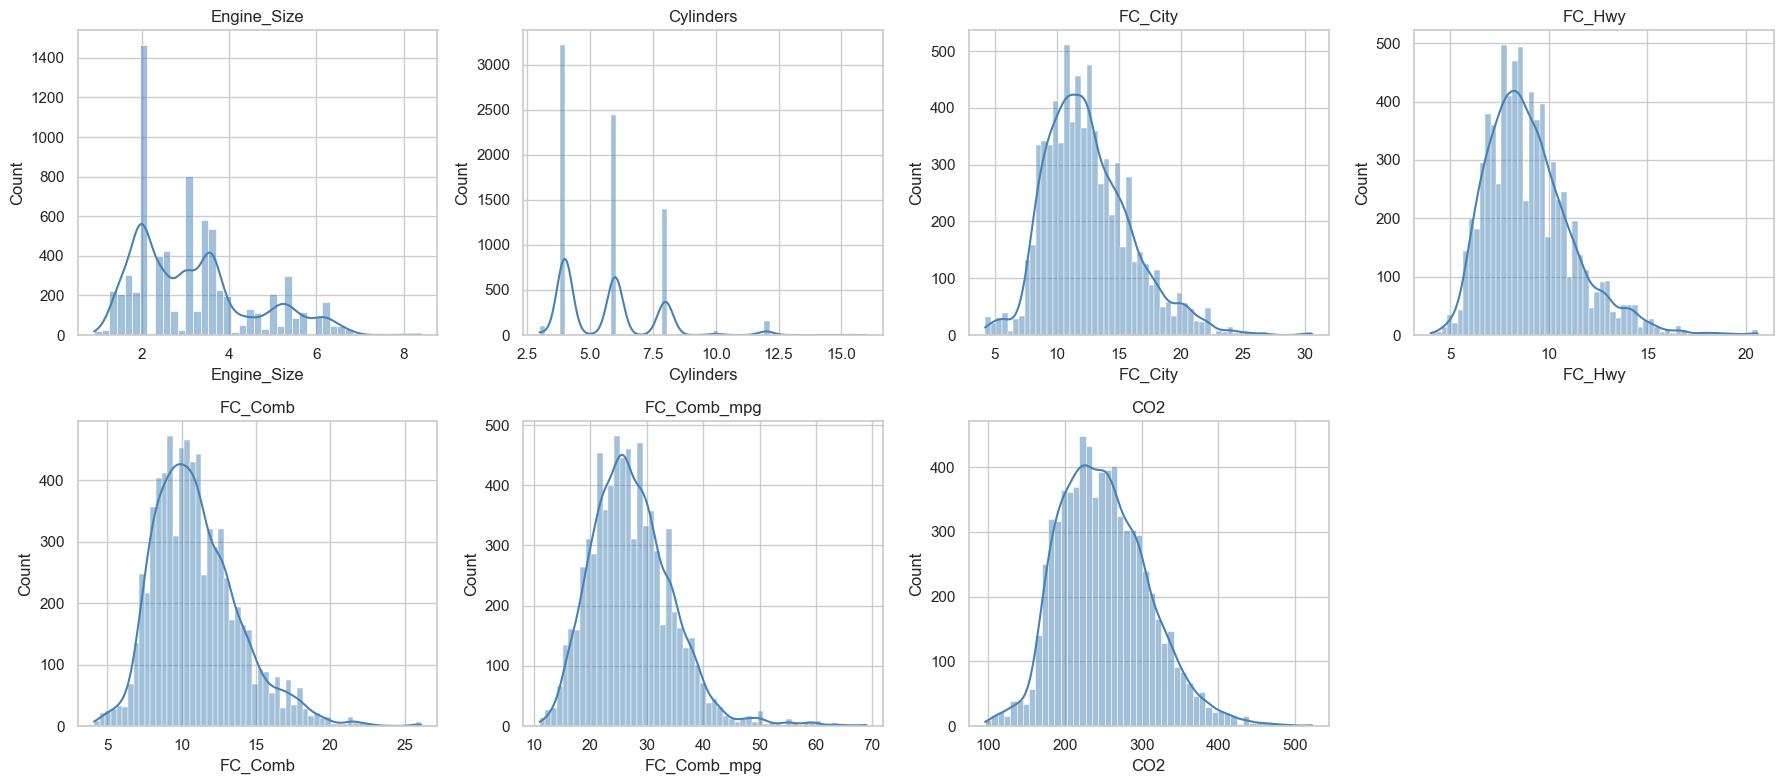

In [5]:
num_cols = ['Engine_Size', 'Cylinders', 'FC_City', 'FC_Hwy', 'FC_Comb', 'FC_Comb_mpg', 'CO2']
fig, axes = plt.subplots(2, 4, figsize=(18, 8)); axes = axes.ravel()
for ax, c in zip(axes, num_cols):
    sns.histplot(df[c], kde=True, ax=ax, color='steelblue'); ax.set_title(c)
axes[-1].axis('off'); plt.tight_layout(); plt.show()

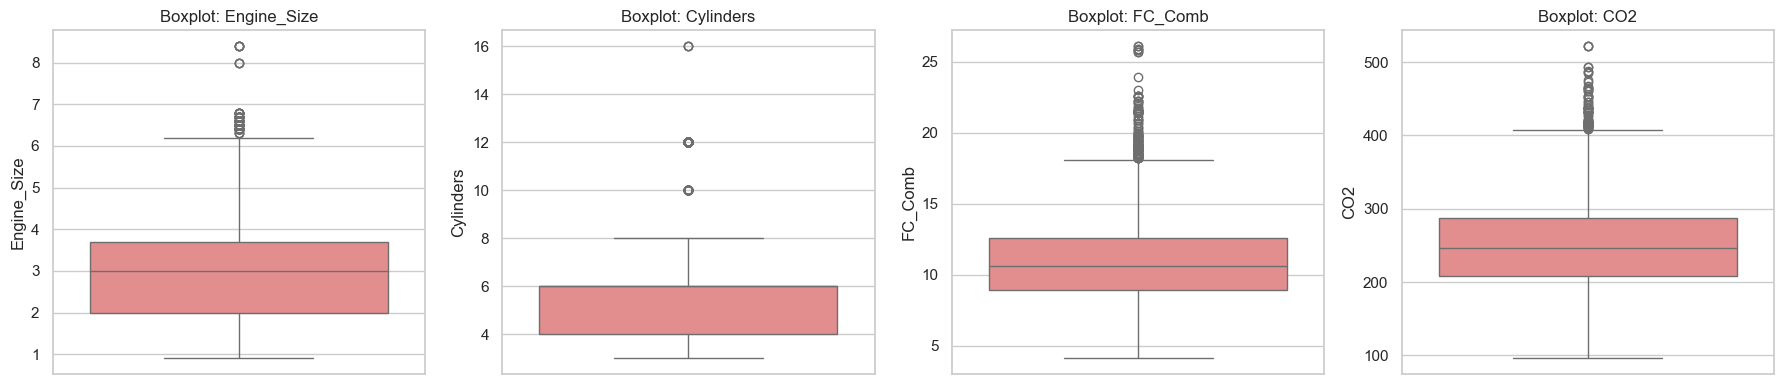

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, c in zip(axes, ['Engine_Size', 'Cylinders', 'FC_Comb', 'CO2']):
    sns.boxplot(y=df[c], ax=ax, color='lightcoral'); ax.set_title(f'Boxplot: {c}')
plt.tight_layout(); plt.show()

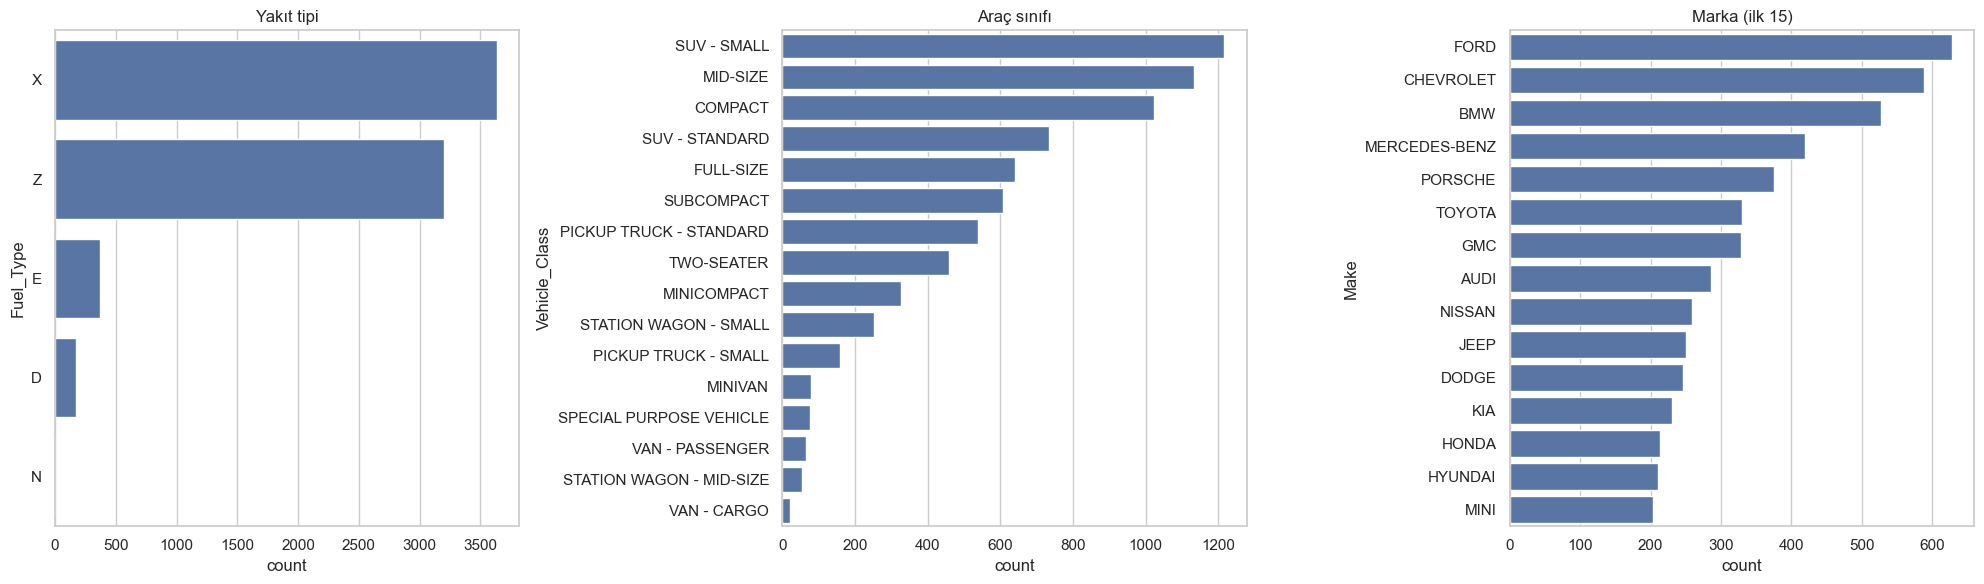

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
sns.countplot(y='Fuel_Type', data=df, order=df['Fuel_Type'].value_counts().index, ax=axes[0])
sns.countplot(y='Vehicle_Class', data=df, order=df['Vehicle_Class'].value_counts().index, ax=axes[1])
sns.countplot(y='Make', data=df, order=df['Make'].value_counts().index[:15], ax=axes[2])
axes[0].set_title('Yakıt tipi'); axes[1].set_title('Araç sınıfı'); axes[2].set_title('Marka (ilk 15)')
plt.tight_layout(); plt.show()

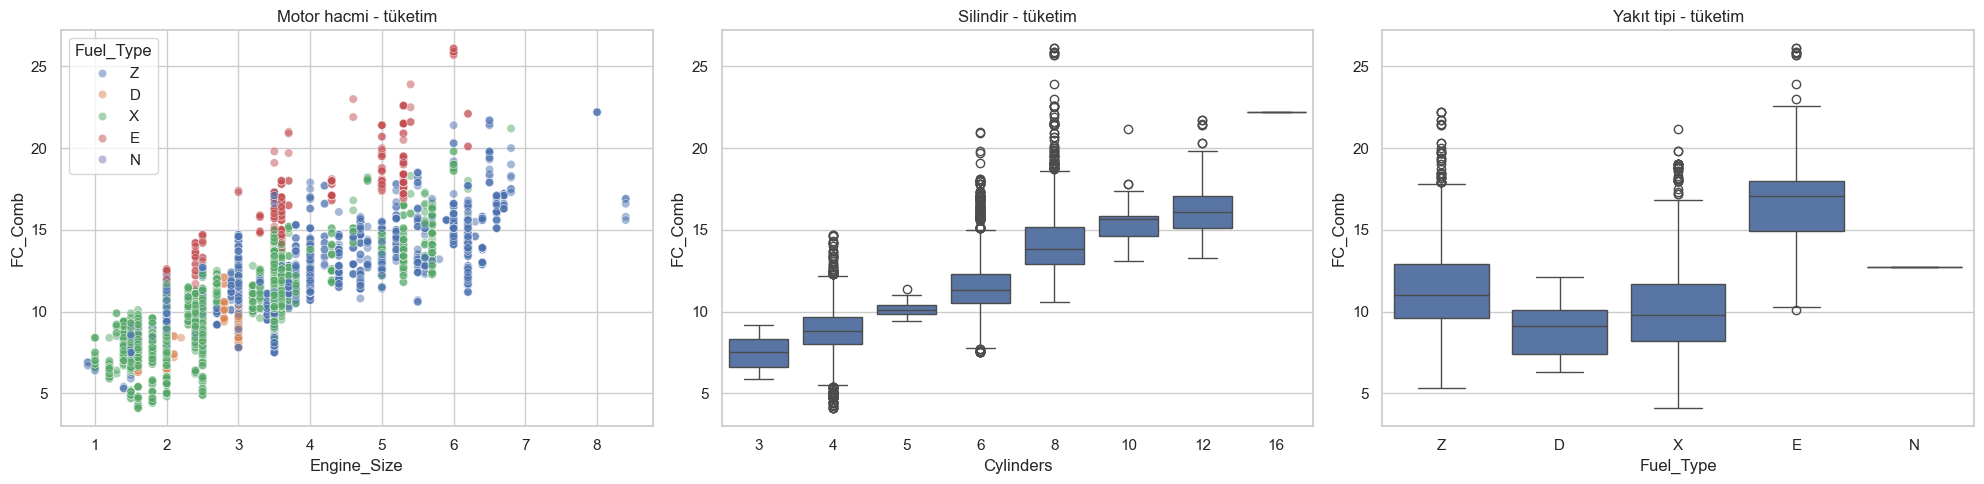

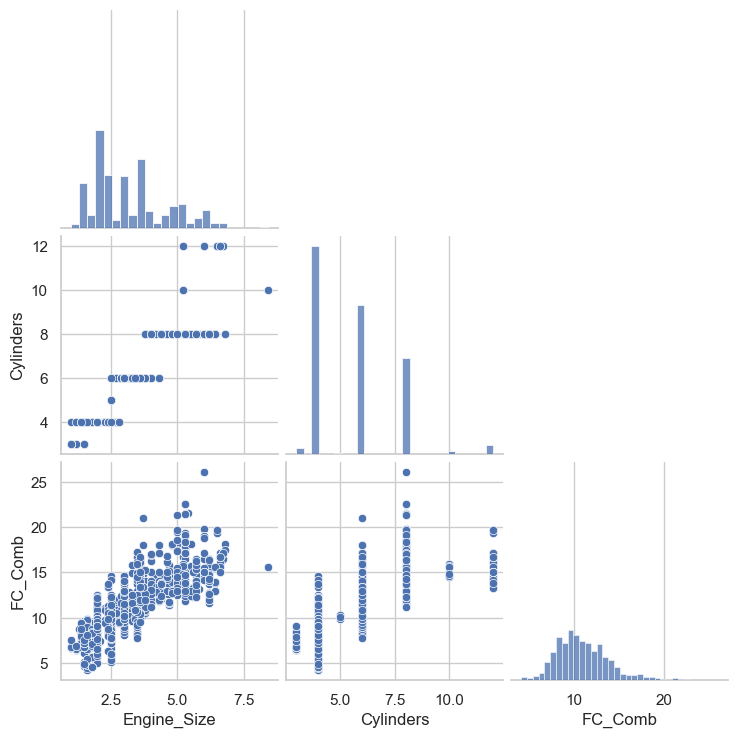

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
sns.scatterplot(data=df, x='Engine_Size', y=TARGET, hue='Fuel_Type', alpha=.5, ax=axes[0])
sns.boxplot(data=df, x='Cylinders', y=TARGET, ax=axes[1])
sns.boxplot(data=df, x='Fuel_Type', y=TARGET, ax=axes[2])
axes[0].set_title('Motor hacmi - tüketim'); axes[1].set_title('Silindir - tüketim'); axes[2].set_title('Yakıt tipi - tüketim')
plt.tight_layout(); plt.show()
sns.pairplot(df[['Engine_Size', 'Cylinders', 'FC_Comb']].sample(min(1500, len(df)), random_state=1), corner=True)
plt.show()

## 5. Veri ön işleme

### 5.1 Eksik değerler
Eksik değer oranı yukarıda gösterildi. **Strateji:** sayısal → medyan, kategorik → en sık değer. (Bu veri setinde eksik yoksa kod hiçbir şeyi değiştirmez ama pipeline'ın parçası olarak durur.)

In [9]:
print('Eksik değer toplamı:', int(df.isna().sum().sum()))
num_f = ['Engine_Size', 'Cylinders']
cat_f = ['Make', 'Vehicle_Class', 'Transmission', 'Fuel_Type']
df[num_f] = SimpleImputer(strategy='median').fit_transform(df[num_f])
df[cat_f] = SimpleImputer(strategy='most_frequent').fit_transform(df[cat_f])
df = df.dropna(subset=[TARGET]).reset_index(drop=True)   # hedefi eksik olan satır varsa atılır

Eksik değer toplamı: 0


### 5.2 Çift (duplicate) kayıtlar

In [10]:
n_dup = df.duplicated().sum()
print(f'Tamamen aynı satır sayısı: {n_dup}  ({n_dup / len(df) * 100:.1f}%)')
df = df.drop_duplicates().reset_index(drop=True)
print('Temizlik sonrası boyut:', df.shape)

Tamamen aynı satır sayısı: 1103  (14.9%)
Temizlik sonrası boyut: (6282, 12)


### 5.3 Aykırı değerler
Yöntemler: **IQR**, **LOF** (çok değişkenli), **Winsorize**, **log dönüşümü**.
Karar mantığı: Büyük V8/V12 spor araçlar ve SUV'lar *gerçek* araçlardır, hata değildir. Bu yüzden satırları **silmek yerine** uç değerleri **winsorize** ediyoruz.

In [11]:
def iqr_report(s):
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    lo, hi = q1 - 1.5 * i, q3 + 1.5 * i
    return pd.Series({'Q1': q1, 'Q3': q3, 'alt_sınır': lo, 'üst_sınır': hi, 'aykırı_sayısı': ((s < lo) | (s > hi)).sum()})
display(pd.DataFrame({c: iqr_report(df[c]) for c in ['Engine_Size', 'Cylinders', TARGET]}).T)

# LOF: çok değişkenli aykırılık
Z = StandardScaler().fit_transform(df[['Engine_Size', 'Cylinders', TARGET]])
lof = LocalOutlierFactor(n_neighbors=20, contamination=0.02)
lof_flag = lof.fit_predict(Z) == -1
print('LOF aykırı sayısı:', lof_flag.sum())
display(df.loc[lof_flag, ['Make', 'Vehicle_Class', 'Engine_Size', 'Cylinders', TARGET]].head(8))

# Dönüşüm: çarpıklık karşılaştırması
print(f'\nÇarpıklık  orijinal: {stats.skew(df[TARGET]):.3f} | log1p: {stats.skew(np.log1p(df[TARGET])):.3f} | sqrt: {stats.skew(np.sqrt(df[TARGET])):.3f}')

,Q1,Q3,alt_sınır,üst_sınır,aykırı_sayısı
Engine_Size,2.0,3.7,-0.55,6.25,121.0
Cylinders,4.0,6.0,1.00,9.00,177.0
FC_Comb,8.9,12.7,3.20,18.40,115.0


LOF aykırı sayısı: 121


,Make,Vehicle_Class,Engine_Size,Cylinders,FC_Comb
39,AUDI,SUV - SMALL,2.0,4.0,10.4
90,BMW,FULL-SIZE,3.0,6.0,10.1
101,BMW,MID-SIZE,3.0,6.0,10.1
105,BMW,COMPACT,3.0,6.0,10.1
275,CHRYSLER,COMPACT,2.4,4.0,10.1
506,HYUNDAI,FULL-SIZE,5.0,8.0,13.2
566,JAGUAR,MINICOMPACT,5.0,8.0,13.5
568,JAGUAR,MINICOMPACT,5.0,8.0,13.5



Çarpıklık  orijinal: 0.924 | log1p: 0.140 | sqrt: 0.491


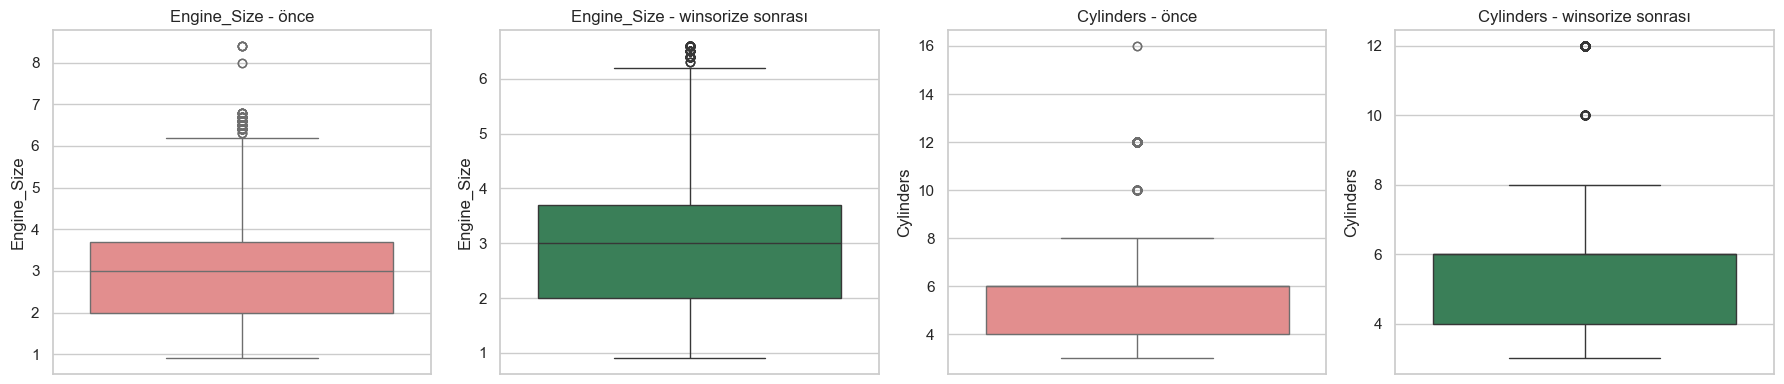

In [12]:
before = df[['Engine_Size', 'Cylinders']].copy()
for c in ['Engine_Size', 'Cylinders']:
    df[c] = np.asarray(winsorize(df[c].values, limits=(0, 0.01)))   # üst %1'i kırp
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for i, c in enumerate(['Engine_Size', 'Cylinders']):
    sns.boxplot(y=before[c], ax=axes[2 * i], color='lightcoral'); axes[2 * i].set_title(f'{c} - önce')
    sns.boxplot(y=df[c], ax=axes[2 * i + 1], color='seagreen'); axes[2 * i + 1].set_title(f'{c} - winsorize sonrası')
plt.tight_layout(); plt.show()

### 5.4 Kategorik değişkenleri kodlama
| Değişken | Yöntem | Neden |
|---|---|---|
| `Fuel_Type`, `Trans_Type` | **One-Hot** | Sırası yok, az sınıf |
| `Vehicle_Class` | **Ordinal** | Küçük → büyük boyut sırası var |
| `Make` | **Label** | 40+ sınıf; one-hot çok sütun üretirdi (ağaç modellerinde sorun olmaz) |
| `Transmission` | **Ayrıştırma** | `AS8` → tip=`AS`, vites sayısı=8 (CVT'de sayı yoktur → 0) |

In [13]:
# Transmission kodunu ayrıştır
parsed = df['Transmission'].astype(str).str.extract(r'^([A-Za-z]+)(\d+)?')
df['Trans_Type'] = parsed[0].str.upper()
df['Gears'] = pd.to_numeric(parsed[1]).fillna(0)

# Ordinal: araç sınıfı (küçükten büyüğe)
CLASS_ORDER = {'TWO-SEATER': 1, 'MINICOMPACT': 2, 'SUBCOMPACT': 3, 'COMPACT': 4, 'MID-SIZE': 5, 'FULL-SIZE': 6,
               'STATION WAGON - SMALL': 3, 'STATION WAGON - MID-SIZE': 5, 'SUV - SMALL': 4, 'SUV - STANDARD': 7,
               'MINIVAN': 6, 'VAN - CARGO': 8, 'VAN - PASSENGER': 8, 'PICKUP TRUCK - SMALL': 6,
               'PICKUP TRUCK - STANDARD': 8, 'SPECIAL PURPOSE VEHICLE': 7}
def class_rank(s):
    s = re.sub(r'\s+', ' ', str(s).upper().replace(':', ' -')).strip()
    if s in CLASS_ORDER: return CLASS_ORDER[s]
    for k, v in sorted(CLASS_ORDER.items(), key=lambda kv: -len(kv[0])):
        if k in s: return v
    return np.nan
df['Vehicle_Class_Ord'] = df['Vehicle_Class'].map(class_rank)
df['Vehicle_Class_Ord'] = df['Vehicle_Class_Ord'].fillna(df['Vehicle_Class_Ord'].median())

# Label: marka
df['Make_Label'] = LabelEncoder().fit_transform(df['Make'])

# One-Hot: yakıt tipi ve şanzıman tipi
df_enc = pd.get_dummies(df, columns=['Fuel_Type', 'Trans_Type'], drop_first=True, dtype=int)
print('Kodlama sonrası boyut:', df_enc.shape)
df_enc.head()

Kodlama sonrası boyut: (6282, 22)


,Make,Model,Vehicle_Class,Engine_Size,Cylinders,Transmission,FC_City,FC_Hwy,FC_Comb,FC_Comb_mpg,...,Vehicle_Class_Ord,Make_Label,Fuel_Type_E,Fuel_Type_N,Fuel_Type_X,Fuel_Type_Z,Trans_Type_AM,Trans_Type_AS,Trans_Type_AV,Trans_Type_M
0,ACURA,ILX,COMPACT,2.0,4.0,AS5,9.9,6.7,8.5,33,...,4,0,0,0,0,1,0,1,0,0
1,ACURA,ILX,COMPACT,2.4,4.0,M6,11.2,7.7,9.6,29,...,4,0,0,0,0,1,0,0,0,1
2,ACURA,ILX HYBRID,COMPACT,1.5,4.0,AV7,6.0,5.8,5.9,48,...,4,0,0,0,0,1,0,0,1,0
3,ACURA,MDX 4WD,SUV - SMALL,3.5,6.0,AS6,12.7,9.1,11.1,25,...,4,0,0,0,0,1,0,1,0,0
4,ACURA,RDX AWD,SUV - SMALL,3.5,6.0,AS6,12.1,8.7,10.6,27,...,4,0,0,0,0,1,0,1,0,0


## 6. Korelasyon, heatmap ve VIF

Kurallar (ödev):
- |korelasyon| **> 0.70** olan çiftlerden **biri** modelden çıkarılır (hedefle korelasyonu daha düşük olan atılır).
- **VIF > 10** olan değişkenler çıkarılır (her turda en yükseği atılıp VIF yeniden hesaplanır).

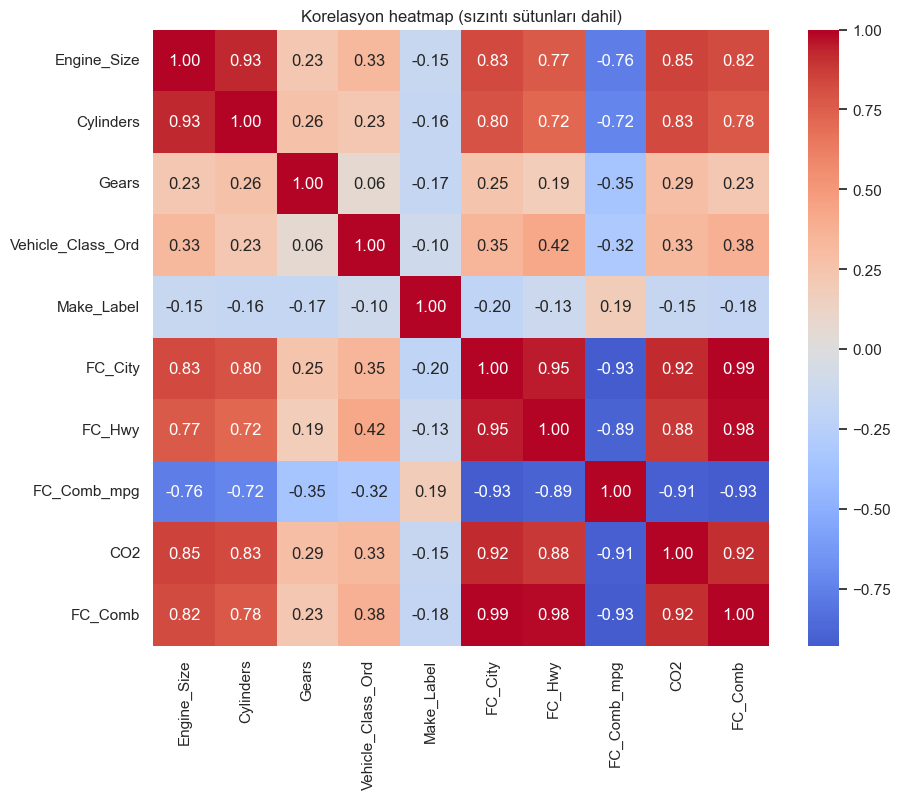

Hedefle korelasyonu çok yüksek (sızıntı) sütunlar modelden çıkarılıyor: ['FC_City', 'FC_Hwy', 'FC_Comb_mpg', 'CO2']


In [14]:
heat_cols = ['Engine_Size', 'Cylinders', 'Gears', 'Vehicle_Class_Ord', 'Make_Label', 'FC_City', 'FC_Hwy', 'FC_Comb_mpg', 'CO2', TARGET]
plt.figure(figsize=(10, 8))
sns.heatmap(df_enc[heat_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True)
plt.title('Korelasyon heatmap (sızıntı sütunları dahil)'); plt.show()

LEAK = ['FC_City', 'FC_Hwy', 'FC_Comb_mpg', 'CO2']
print('Hedefle korelasyonu çok yüksek (sızıntı) sütunlar modelden çıkarılıyor:', LEAK)

Başlangıç özellikleri: ['Engine_Size', 'Cylinders', 'Gears', 'Vehicle_Class_Ord', 'Make_Label', 'Fuel_Type_E', 'Fuel_Type_N', 'Fuel_Type_X', 'Fuel_Type_Z', 'Trans_Type_AM', 'Trans_Type_AS', 'Trans_Type_AV', 'Trans_Type_M']

VIF (filtre öncesi):


,feature,VIF
8,Fuel_Type_Z,11.898534
7,Fuel_Type_X,11.566876
0,Engine_Size,8.746941
1,Cylinders,8.415703
5,Fuel_Type_E,3.216276
12,Trans_Type_M,1.859808
11,Trans_Type_AV,1.842184
10,Trans_Type_AS,1.814908
2,Gears,1.724737
3,Vehicle_Class_Ord,1.647345



[Korelasyon > 0.70 filtresi]
|r|=0.93  (Engine_Size ~ Cylinders)  -> çıkarıldı: Cylinders
|r|=0.86  (Fuel_Type_X ~ Fuel_Type_Z)  -> çıkarıldı: Fuel_Type_Z

[VIF > 10 filtresi]
Çıkarılan yok

Kalan özellikler: ['Engine_Size', 'Gears', 'Vehicle_Class_Ord', 'Make_Label', 'Fuel_Type_E', 'Fuel_Type_N', 'Fuel_Type_X', 'Trans_Type_AM', 'Trans_Type_AS', 'Trans_Type_AV', 'Trans_Type_M']


,feature,VIF
10,Trans_Type_M,1.842685
9,Trans_Type_AV,1.825687
8,Trans_Type_AS,1.768387
1,Gears,1.719622
2,Vehicle_Class_Ord,1.581202
6,Fuel_Type_X,1.541763
7,Trans_Type_AM,1.516794
0,Engine_Size,1.347156
4,Fuel_Type_E,1.269706
3,Make_Label,1.083835


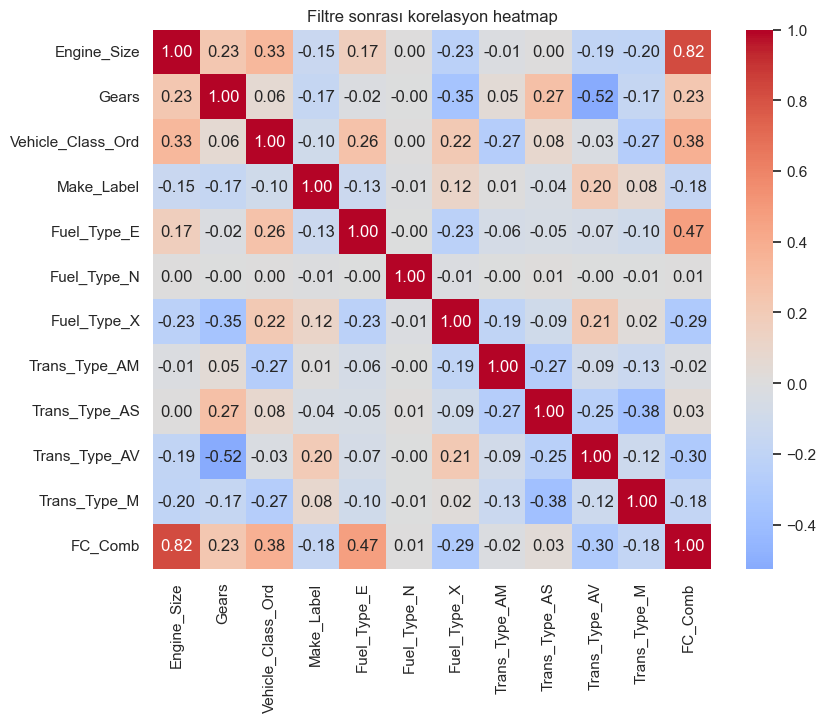

In [15]:
def corr_filter(X, y, thr=0.70):
    X = X.copy(); log = []
    while True:
        c = X.corr().abs()
        pairs = [(a, b, c.loc[a, b]) for i, a in enumerate(c.index) for b in c.columns[i + 1:] if c.loc[a, b] > thr]
        if not pairs: break
        a, b, r = max(pairs, key=lambda t: t[2])
        drop = a if abs(X[a].corr(y)) < abs(X[b].corr(y)) else b
        log.append(f'|r|={r:.2f}  ({a} ~ {b})  -> çıkarıldı: {drop}')
        X = X.drop(columns=drop)
    return X, log

def vif_table(X):
    Xc = sm.add_constant(X.astype(float))
    return pd.DataFrame({'feature': X.columns,
                         'VIF': [variance_inflation_factor(Xc.values, i + 1) for i in range(X.shape[1])]}).sort_values('VIF', ascending=False)

def vif_filter(X, thr=10):
    X = X.copy(); log = []
    while True:
        t = vif_table(X)
        if t['VIF'].iloc[0] <= thr: break
        log.append(f"VIF={t['VIF'].iloc[0]:.1f} -> çıkarıldı: {t['feature'].iloc[0]}")
        X = X.drop(columns=t['feature'].iloc[0])
    return X, log

base_feats = [c for c in df_enc.columns if c not in LEAK + [TARGET, 'Make', 'Model', 'Vehicle_Class', 'Transmission']]
X_base, y_all = df_enc[base_feats], df_enc[TARGET]
print('Başlangıç özellikleri:', base_feats)
print('\nVIF (filtre öncesi):'); display(vif_table(X_base))

X_c, log_c = corr_filter(X_base, y_all)
print('\n[Korelasyon > 0.70 filtresi]'); print('\n'.join(log_c) or 'Çıkarılan yok')
X_v, log_v = vif_filter(X_c)
print('\n[VIF > 10 filtresi]'); print('\n'.join(log_v) or 'Çıkarılan yok')
print('\nKalan özellikler:', list(X_v.columns))
display(vif_table(X_v))

plt.figure(figsize=(9, 7))
sns.heatmap(X_v.assign(**{TARGET: y_all}).corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Filtre sonrası korelasyon heatmap'); plt.show()

## 7. Feature engineering ve feature selection

### 7.1 Feature engineering
- `Disp_per_Cyl` = motor hacmi / silindir (silindir başına hacim; silindir sütunu filtrede atılmış olsa bile bilgisi geri gelir)
- `Make_Freq` = markanın veri setindeki frekansı (marka popülerliği/segmenti için proxy)
- `Eng_x_Gears` = motor hacmi × vites sayısı (etkileşim terimi)

Yeni değişkenler tekrar korelasyon/VIF filtresinden geçirilir.

In [16]:
fe = df_enc.copy()
fe['Disp_per_Cyl'] = fe['Engine_Size'] / fe['Cylinders']
fe['Make_Freq'] = fe['Make'].map(fe['Make'].value_counts())
fe['Eng_x_Gears'] = fe['Engine_Size'] * fe['Gears']

cand = list(X_v.columns) + ['Disp_per_Cyl', 'Make_Freq', 'Eng_x_Gears']
X_fe, l1 = corr_filter(fe[cand], fe[TARGET]); X_fe, l2 = vif_filter(X_fe)
print('\n'.join(l1 + l2) or 'Yeni değişkenlerden çıkarılan yok')
print('Aday özellik sayısı:', X_fe.shape[1], '\n', list(X_fe.columns))

|r|=0.90  (Engine_Size ~ Eng_x_Gears)  -> çıkarıldı: Eng_x_Gears
|r|=0.74  (Engine_Size ~ Disp_per_Cyl)  -> çıkarıldı: Disp_per_Cyl
Aday özellik sayısı: 12 
 ['Engine_Size', 'Gears', 'Vehicle_Class_Ord', 'Make_Label', 'Fuel_Type_E', 'Fuel_Type_N', 'Fuel_Type_X', 'Trans_Type_AM', 'Trans_Type_AS', 'Trans_Type_AV', 'Trans_Type_M', 'Make_Freq']


### 7.2 Train / Validation / Test bölmesi
Veri sızıntısını önlemek için **bölmeyi feature selection'dan önce** yapıyoruz; seçim yalnızca **train** üzerinde hesaplanır (aksi halde val/test bilgisi seçime karışır). Oran: **%70 / %15 / %15**.

In [17]:
y_all = fe[TARGET]
X_train, X_tmp, y_train, y_tmp = train_test_split(X_fe, y_all, test_size=0.30, random_state=RANDOM_STATE)
X_val, X_test, y_val, y_test = train_test_split(X_tmp, y_tmp, test_size=0.50, random_state=RANDOM_STATE)
print(f'Train: {X_train.shape} | Val: {X_val.shape} | Test: {X_test.shape}')

Train: (4397, 12) | Val: (942, 12) | Test: (943, 12)


### 7.3 Feature selection
Kullanılan yöntemler: **Filter** (Pearson, Mutual Information) · **Wrapper** (RFE) · **Embedded** (Lasso, Random Forest önemi, XGBoost önemi) · **PCA** (boyut indirgeme analizi).
Her yöntemin sıralaması birleştirilir; ortalama sırası en iyi olan özellikler seçilir.

,Pearson,MI,RF_imp,XGB_imp,Lasso_|coef|,RFE_rank,ortalama_sıra
Engine_Size,0.8199,1.0003,0.7335,0.1972,2.0506,1,1.1667
Fuel_Type_E,0.4854,0.1074,0.1169,0.6115,0.9160,1,2.3333
Vehicle_Class_Ord,0.3906,0.2870,0.0353,0.0135,0.2250,1,3.6667
Trans_Type_AV,0.3062,0.0820,0.0105,0.0834,0.4255,2,4.5000
Gears,0.2400,0.1806,0.0261,0.0128,0.0546,1,5.3333
Make_Freq,0.1337,0.4826,0.0341,0.0218,0.0000,1,5.4167
Fuel_Type_X,0.3057,0.0937,0.0079,0.0193,0.1694,3,5.5000
Make_Label,0.1674,0.5669,0.0222,0.0130,0.0052,1,5.6667
Trans_Type_AM,0.0347,0.0390,0.0055,0.0138,0.0151,4,7.6667
Trans_Type_M,0.1679,0.0324,0.0026,0.0047,0.0117,6,8.8333



Seçilen 6 özellik: ['Engine_Size', 'Fuel_Type_E', 'Vehicle_Class_Ord', 'Trans_Type_AV', 'Gears', 'Make_Freq']


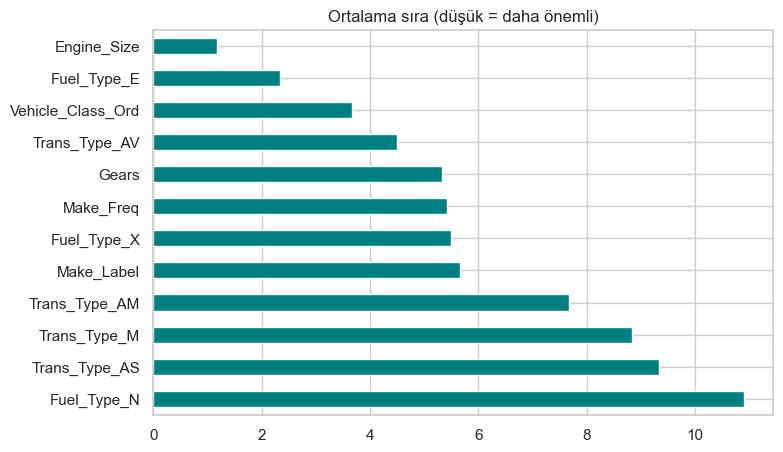

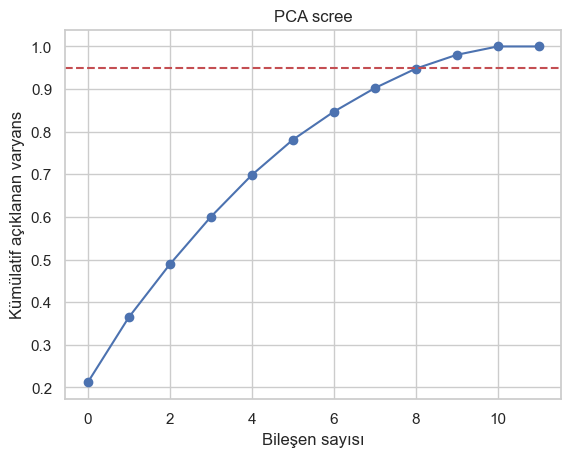

%95 varyans için gereken bileşen: 10


In [18]:
feats = list(X_train.columns)
sc = StandardScaler().fit(X_train); Xs = pd.DataFrame(sc.transform(X_train), columns=feats)

sel = pd.DataFrame(index=feats)
sel['Pearson'] = [abs(np.corrcoef(X_train[f], y_train)[0, 1]) for f in feats]
sel['MI'] = mutual_info_regression(X_train, y_train, random_state=RANDOM_STATE)
sel['RF_imp'] = RandomForestRegressor(200, n_jobs=-1, random_state=RANDOM_STATE).fit(X_train, y_train).feature_importances_
sel['XGB_imp'] = XGBRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1).fit(X_train, y_train).feature_importances_
sel['Lasso_|coef|'] = np.abs(LassoCV(cv=5, random_state=RANDOM_STATE).fit(Xs, y_train).coef_)
k = max(5, len(feats) // 2)
rfe = RFE(RandomForestRegressor(100, n_jobs=-1, random_state=RANDOM_STATE), n_features_to_select=k).fit(X_train, y_train)
sel['RFE_rank'] = rfe.ranking_

rank = sel.drop(columns='RFE_rank').rank(ascending=False)
rank['RFE'] = sel['RFE_rank']
sel['ortalama_sıra'] = rank.mean(axis=1)
sel = sel.sort_values('ortalama_sıra')
display(sel.round(4))

selected = list(sel.index[:k])
print(f'\nSeçilen {k} özellik:', selected)

fig, ax = plt.subplots(figsize=(8, 5))
sel['ortalama_sıra'].sort_values(ascending=False).plot.barh(ax=ax, color='teal'); ax.set_title('Ortalama sıra (düşük = daha önemli)')
plt.show()

# PCA (analiz amaçlı - modelde kullanılmıyor, yorumlanabilirliği bozar)
pca = PCA().fit(Xs)
plt.plot(np.cumsum(pca.explained_variance_ratio_), marker='o'); plt.axhline(.95, color='r', ls='--')
plt.xlabel('Bileşen sayısı'); plt.ylabel('Kümülatif açıklanan varyans'); plt.title('PCA scree'); plt.show()
print('%95 varyans için gereken bileşen:', int(np.argmax(np.cumsum(pca.explained_variance_ratio_) >= .95)) + 1)

X_train_s, X_val_s, X_test_s = X_train[selected], X_val[selected], X_test[selected]

## 8. Modeller (12 adet) ve regresyon metrikleri

**Metrikler:** MAE, MSE, RMSE, R², MAPE (hepsi hedefin birimi L/100 km cinsinden yorumlanır; R² birimsiz).
Mesafe/ölçek duyarlı modeller (Linear, Ridge, Lasso, ElasticNet, KNN, SVR) `StandardScaler` ile pipeline içinde çalışır.

In [19]:
def scaled(m): return Pipeline([('sc', StandardScaler()), ('m', m)])

models = {
    'Linear Regression': scaled(LinearRegression()),
    'Ridge':             scaled(Ridge(alpha=1.0)),
    'Lasso':             scaled(Lasso(alpha=0.01)),
    'ElasticNet':        scaled(ElasticNet(alpha=0.01, l1_ratio=0.5)),
    'KNN':               scaled(KNeighborsRegressor(n_neighbors=7)),
    'SVR':               scaled(SVR(C=5, epsilon=0.1)),
    'Decision Tree':     DecisionTreeRegressor(random_state=RANDOM_STATE),
    'Random Forest':     RandomForestRegressor(300, n_jobs=-1, random_state=RANDOM_STATE),
    'Extra Trees':       ExtraTreesRegressor(300, n_jobs=-1, random_state=RANDOM_STATE),
    'Gradient Boosting': GradientBoostingRegressor(random_state=RANDOM_STATE),
    'AdaBoost':          AdaBoostRegressor(random_state=RANDOM_STATE),
    'XGBoost':           XGBRegressor(n_estimators=300, learning_rate=0.05, random_state=RANDOM_STATE, n_jobs=-1),
    'LightGBM':          LGBMRegressor(n_estimators=300, learning_rate=0.05, random_state=RANDOM_STATE, verbose=-1, n_jobs=-1),
}

def metrics(y, p):
    mse = mean_squared_error(y, p)
    return dict(MAE=mean_absolute_error(y, p), MSE=mse, RMSE=np.sqrt(mse), R2=r2_score(y, p),
                MAPE=mean_absolute_percentage_error(y, p) * 100)

rows = []
for name, m in models.items():
    t0 = time.time(); m.fit(X_train_s, y_train); dt = time.time() - t0
    tr, va, te = (metrics(y, m.predict(X)) for X, y in [(X_train_s, y_train), (X_val_s, y_val), (X_test_s, y_test)])
    rows.append({'Model': name, 'Train_R2': tr['R2'], **{f'Val_{k}': v for k, v in va.items()},
                 **{f'Test_{k}': v for k, v in te.items()}, 'Süre_sn': dt})
results = pd.DataFrame(rows).sort_values('Val_RMSE').reset_index(drop=True)
display(results.round(4))

,Model,Train_R2,Val_MAE,Val_MSE,Val_RMSE,Val_R2,Val_MAPE,Test_MAE,Test_MSE,Test_RMSE,Test_R2,Test_MAPE,Süre_sn
0,Random Forest,0.9619,0.5060,0.5182,0.7198,0.9351,4.8391,0.5062,0.5513,0.7425,0.9423,4.9092,0.2566
1,Extra Trees,0.9632,0.4996,0.5300,0.7280,0.9336,4.7715,0.5003,0.5607,0.7488,0.9413,4.8471,0.1667
2,Decision Tree,0.9632,0.4968,0.5313,0.7289,0.9335,4.7155,0.5054,0.5789,0.7609,0.9394,4.8805,0.0040
3,XGBoost,0.9526,0.5646,0.5866,0.7659,0.9265,5.5025,0.5307,0.5564,0.7459,0.9418,5.1843,0.1512
4,LightGBM,0.9430,0.5983,0.6629,0.8142,0.9170,5.8755,0.5876,0.6533,0.8083,0.9316,5.7213,0.3462
5,KNN,0.9269,0.6822,0.8871,0.9419,0.8889,6.5229,0.6582,0.8326,0.9125,0.9129,6.2954,0.0041
6,Gradient Boosting,0.9040,0.7482,0.9957,0.9979,0.8753,7.2923,0.6998,0.8515,0.9228,0.9109,6.8037,0.1257
7,SVR,0.8627,0.8226,1.3010,1.1406,0.8371,7.8204,0.7900,1.2483,1.1173,0.8694,7.4542,0.4888
8,AdaBoost,0.8155,1.0390,1.7544,1.3245,0.7803,9.9178,1.0245,1.7055,1.3060,0.8215,9.7413,0.1064
9,Ridge,0.8110,1.0069,1.7900,1.3379,0.7758,9.5101,0.9719,1.7200,1.3115,0.8200,9.1541,0.0040


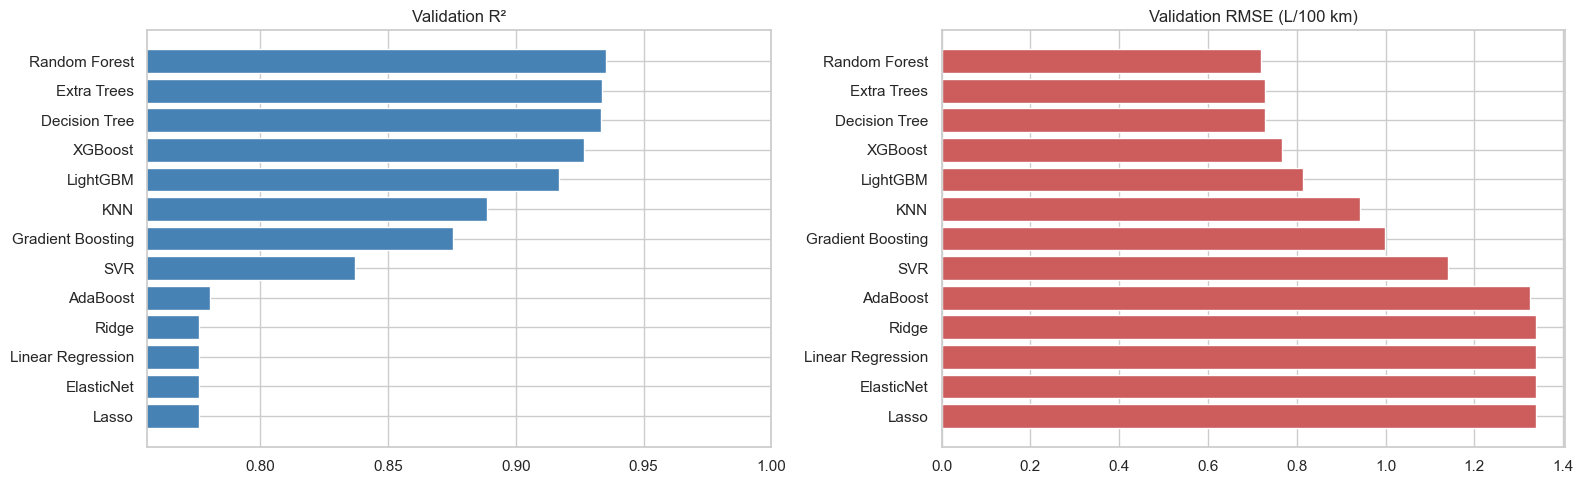

Validation RMSE'ye göre en iyi model: Random Forest


In [20]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
r = results.sort_values('Val_R2')
axes[0].barh(r['Model'], r['Val_R2'], color='steelblue'); axes[0].set_title('Validation R²'); axes[0].set_xlim(r['Val_R2'].min() - .02, 1)
r = results.sort_values('Val_RMSE', ascending=False)
axes[1].barh(r['Model'], r['Val_RMSE'], color='indianred'); axes[1].set_title('Validation RMSE (L/100 km)')
plt.tight_layout(); plt.show()
best_name = results.loc[0, 'Model']
print('Validation RMSE\'ye göre en iyi model:', best_name)

**Yorum için ipuçları:** Train R² ile Val R² arasındaki fark büyükse aşırı öğrenme (overfitting) vardır (Decision Tree tipik örnektir).
Doğrusal modeller ile ağaç tabanlı modellerin farkı, tüketimin özelliklerle **doğrusal olmayan** ilişkisini gösterir.

## 9. Hiperparametre optimizasyonu

| Yöntem | Mantık | Artı / Eksi |
|---|---|---|
| **GridSearch** | Tüm kombinasyonları dener | Kapsamlı ama parametre sayısıyla üstel büyür |
| **RandomSearch** | Rastgele kombinasyon dener | Hızlı, geniş alanı tarar, iyiyi garanti etmez |
| **Bayesian / Optuna (TPE)** | Önceki denemelerden öğrenip umut vadeden bölgeye yönelir | Az denemeyle iyi sonuç; **bu ödevde ana yöntemimiz** |

Önce küçük bir karşılaştırma (Grid vs Random vs Optuna), sonra Optuna ile en güçlü model olan **XGBoost** ayarlanır. Tüm aramalar **yalnızca train** üzerinde 3-katlı CV ile yapılır.

In [21]:
cv = KFold(3, shuffle=True, random_state=RANDOM_STATE)
comp = []

t0 = time.time()
gs = GridSearchCV(RandomForestRegressor(100, n_jobs=-1, random_state=RANDOM_STATE),
                  {'max_depth': [8, 16, None], 'min_samples_leaf': [1, 3, 5], 'max_features': [0.5, 1.0]},
                  cv=cv, scoring='neg_root_mean_squared_error', n_jobs=-1).fit(X_train_s, y_train)
comp.append(['GridSearch (RF)', -gs.best_score_, time.time() - t0, gs.best_params_])

t0 = time.time()
rs = RandomizedSearchCV(RandomForestRegressor(100, n_jobs=-1, random_state=RANDOM_STATE),
                        {'max_depth': [6, 8, 12, 16, 20, None], 'min_samples_leaf': [1, 2, 3, 5, 8], 'max_features': [0.3, 0.5, 0.7, 1.0],
                         'n_estimators': [100, 200, 300]},
                        n_iter=15, cv=cv, scoring='neg_root_mean_squared_error', n_jobs=-1, random_state=RANDOM_STATE).fit(X_train_s, y_train)
comp.append(['RandomSearch (RF)', -rs.best_score_, time.time() - t0, rs.best_params_])

,Yöntem,CV_RMSE,Süre_sn,En iyi parametreler
0,GridSearch (RF),0.739173,6.566645,"{'max_depth': 16, 'max_features': 0.5, 'min_sa..."
1,RandomSearch (RF),0.739724,2.423967,"{'n_estimators': 300, 'min_samples_leaf': 1, '..."
2,Optuna/TPE (XGBoost),0.734387,52.365187,"{'n_estimators': 423, 'learning_rate': 0.10692..."


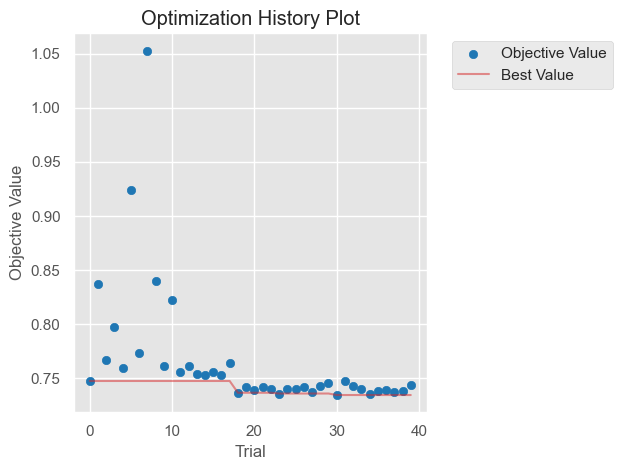

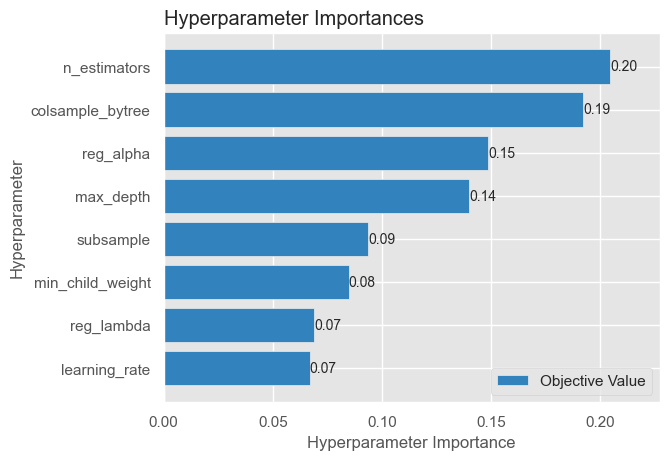

In [22]:
def objective(trial):
    p = dict(n_estimators=trial.suggest_int('n_estimators', 200, 800),
             learning_rate=trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
             max_depth=trial.suggest_int('max_depth', 3, 10),
             min_child_weight=trial.suggest_int('min_child_weight', 1, 10),
             subsample=trial.suggest_float('subsample', 0.6, 1.0),
             colsample_bytree=trial.suggest_float('colsample_bytree', 0.6, 1.0),
             reg_alpha=trial.suggest_float('reg_alpha', 1e-3, 10, log=True),
             reg_lambda=trial.suggest_float('reg_lambda', 1e-3, 10, log=True))
    m = XGBRegressor(**p, random_state=RANDOM_STATE, n_jobs=-1)
    return -cross_val_score(m, X_train_s, y_train, cv=cv, scoring='neg_root_mean_squared_error').mean()

t0 = time.time()
study = optuna.create_study(direction='minimize', sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
study.optimize(objective, n_trials=40)
comp.append(['Optuna/TPE (XGBoost)', study.best_value, time.time() - t0, study.best_params])
display(pd.DataFrame(comp, columns=['Yöntem', 'CV_RMSE', 'Süre_sn', 'En iyi parametreler']))

optuna.visualization.matplotlib.plot_optimization_history(study); plt.show()
optuna.visualization.matplotlib.plot_param_importances(study); plt.show()

,XGBoost (varsayılan),XGBoost (Optuna)
Val_MAE,0.5646,0.5008
Val_MSE,0.5866,0.5095
Val_RMSE,0.7659,0.7138
Val_R2,0.9265,0.9362
Val_MAPE,5.5025,4.8032
Test_MAE,0.5307,0.4972
Test_MSE,0.5564,0.5212
Test_RMSE,0.7459,0.7219
Test_R2,0.9418,0.9455
Test_MAPE,5.1843,4.8295


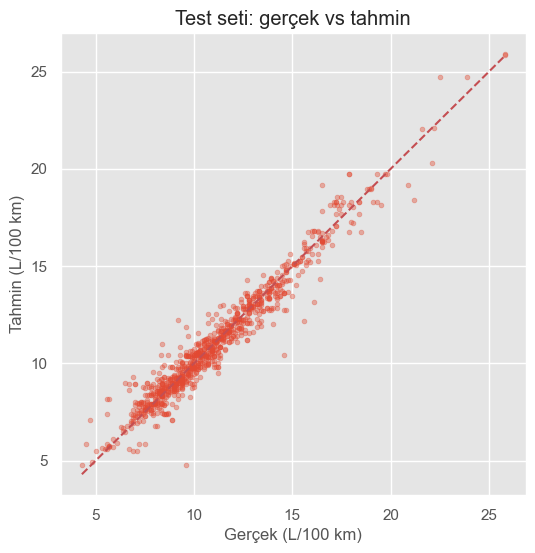

In [23]:
best_xgb = XGBRegressor(**study.best_params, random_state=RANDOM_STATE, n_jobs=-1).fit(X_train_s, y_train)
base_xgb = models['XGBoost']
cmp = pd.DataFrame({
    'XGBoost (varsayılan)': {**{f'Val_{k}': v for k, v in metrics(y_val, base_xgb.predict(X_val_s)).items()},
                             **{f'Test_{k}': v for k, v in metrics(y_test, base_xgb.predict(X_test_s)).items()}},
    'XGBoost (Optuna)':     {**{f'Val_{k}': v for k, v in metrics(y_val, best_xgb.predict(X_val_s)).items()},
                             **{f'Test_{k}': v for k, v in metrics(y_test, best_xgb.predict(X_test_s)).items()}}})
display(cmp.round(4))

plt.figure(figsize=(6, 6))
plt.scatter(y_test, best_xgb.predict(X_test_s), alpha=.4, s=12)
lim = [y_test.min(), y_test.max()]; plt.plot(lim, lim, 'r--')
plt.xlabel('Gerçek (L/100 km)'); plt.ylabel('Tahmin (L/100 km)'); plt.title('Test seti: gerçek vs tahmin'); plt.show()

## 10. Kara kutu (black box) model nedir?

**Kara kutu model:** Girdiden çıktıyı üretir ama *bu kararı neden verdiği* insanın doğrudan okuyabileceği bir biçimde görünmez.
İçinde yüzlerce ağaç (Random Forest, XGBoost) veya milyonlarca ağırlık (sinir ağı) vardır; tek bir formül veya kural olarak okunamaz.

| | Şeffaf model (Linear / Decision Tree) | Kara kutu (RF, XGBoost, SVR, NN) |
|---|---|---|
| Açıklama | Katsayı: "motor hacmi 1 L artarsa tüketim ≈ +X L/100 km" | Katsayı yok |
| Doğruluk | Genelde daha düşük | Genelde daha yüksek |

**Feature importance'ın sınırı:** Bu modeller katsayı vermez; en fazla bir özelliğin **ne kadar önemli** olduğunu söyler
(örn. "motor hacmi %45 önemli"). Ama **neyi/nasıl** etkilediğini söylemez: tüketimi *artırır mı azaltır mı*, ilişki doğrusal mı, eşik var mı, hangi araçta etkisi daha büyük?
Ayrıca ağaç tabanlı importance, korele değişkenlerde yanıltıcı olabilir.

Bu boşluğu **XAI (Açıklanabilir Yapay Zekâ)** yöntemleri doldurur.

## 11. XAI: SHAP, LIME ve PDP

- **SHAP:** Oyun teorisindeki Shapley değerleriyle her özelliğin *her tahmine* katkısını (+/− yönüyle) verir. Hem **global** hem **lokal** açıklama sunar.
- **LIME:** Tek bir tahminin çevresinde basit (doğrusal) bir vekil model kurup o tahmini açıklar (**lokal**).
- **PDP/ICE:** Bir özellik değişirken ortalama tahminin nasıl değiştiğini çizer (**global**).

> **Not (GAN):** Ödev metninde XAI yöntemleri arasında "GAN" yazıyor. GAN (Generative Adversarial Network) bir *açıklama* yöntemi değil, sentetik veri/görüntü üreten bir **üretici modeldir**. Muhtemelen **Grad-CAM** (görüntü modelleri için) ya da **GAM** kastedilmiştir; bunu hocaya teyit ettirmenizi öneririm. Tablo verisinde SHAP + LIME + PDP yeterli ve doğrudur.

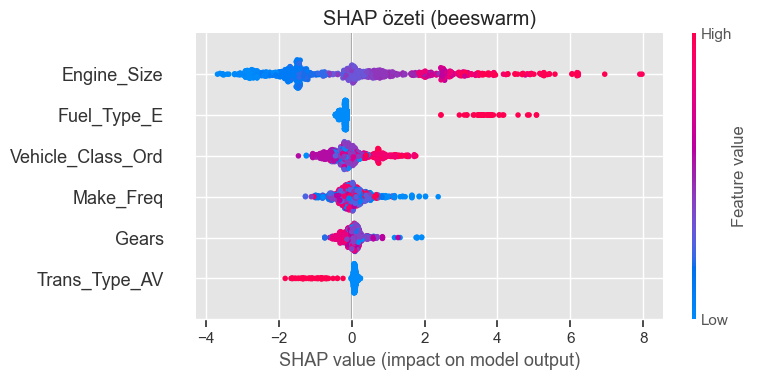

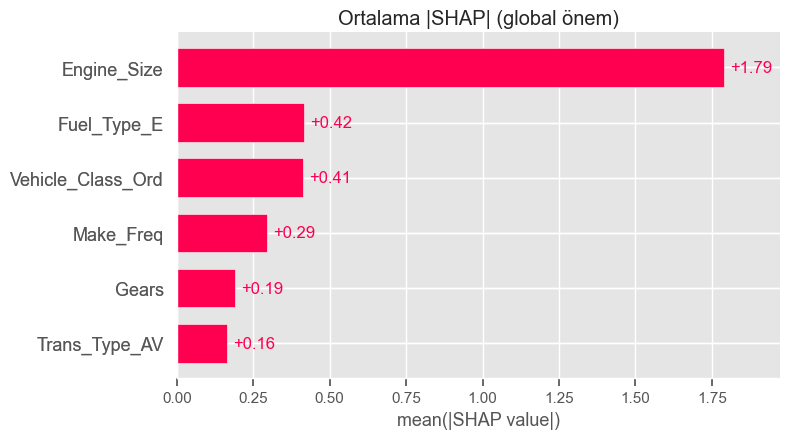

In [24]:
explainer = shap.TreeExplainer(best_xgb)
sv = explainer(X_test_s)

shap.plots.beeswarm(sv, max_display=15, show=False); plt.title('SHAP özeti (beeswarm)'); plt.tight_layout(); plt.show()
shap.plots.bar(sv, max_display=15, show=False); plt.title('Ortalama |SHAP| (global önem)'); plt.tight_layout(); plt.show()

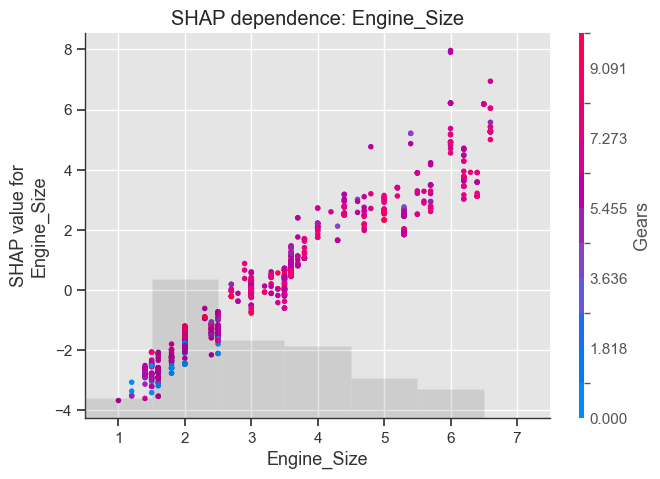

Örnek araç:


,Engine_Size,Fuel_Type_E,Vehicle_Class_Ord,Trans_Type_AV,Gears,Make_Freq
4825,3.0,0,3,0,8.0,263


Gerçek: 9.80 | Tahmin: 10.61 L/100 km


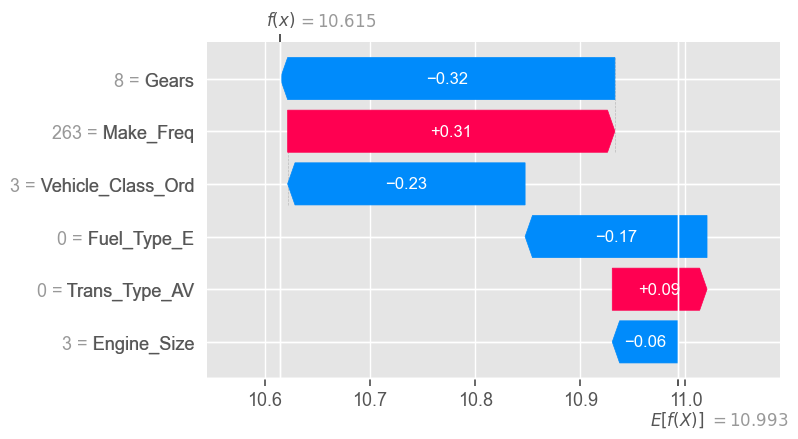

In [25]:
top_feat = X_test_s.columns[np.abs(sv.values).mean(0).argmax()]
shap.plots.scatter(sv[:, top_feat], color=sv, show=False); plt.title(f'SHAP dependence: {top_feat}'); plt.show()

i = 0   # açıklanacak test örneği
print('Örnek araç:'); display(X_test_s.iloc[[i]])
print(f'Gerçek: {y_test.iloc[i]:.2f} | Tahmin: {best_xgb.predict(X_test_s.iloc[[i]])[0]:.2f} L/100 km')
shap.plots.waterfall(sv[i], show=False); plt.tight_layout(); plt.show()

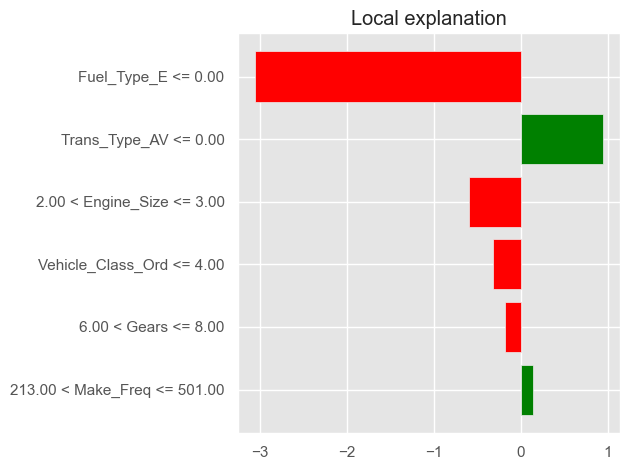

LIME katkıları:
  Fuel_Type_E <= 0.00                 -3.059
  Trans_Type_AV <= 0.00               +0.938
  2.00 < Engine_Size <= 3.00          -0.604
  Vehicle_Class_Ord <= 4.00           -0.328
  6.00 < Gears <= 8.00                -0.190
  213.00 < Make_Freq <= 501.00        +0.138


In [26]:
lime_exp = LimeTabularExplainer(X_train_s.values, feature_names=list(X_train_s.columns), mode='regression', random_state=RANDOM_STATE)
exp = lime_exp.explain_instance(X_test_s.values[i], best_xgb.predict, num_features=8)
exp.as_pyplot_figure(); plt.tight_layout(); plt.show()
print('LIME katkıları:'); 
for f, w in exp.as_list(): print(f'  {f:35s} {w:+.3f}')

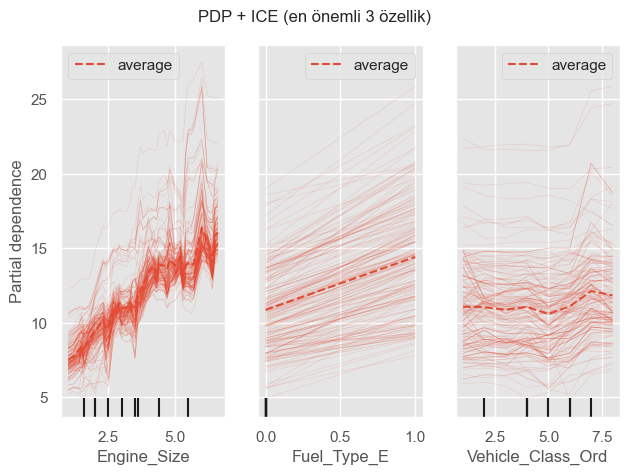

In [27]:
top3 = list(X_test_s.columns[np.argsort(-np.abs(sv.values).mean(0))[:3]])
pdp_data = X_test_s.astype(np.float64)

PartialDependenceDisplay.from_estimator(
    best_xgb,
    pdp_data,
    top3,
    kind='both',
    subsample=200,
    random_state=RANDOM_STATE,
    ice_lines_kw={'alpha': .15}
)
plt.suptitle('PDP + ICE (en önemli 3 özellik)'); plt.tight_layout(); plt.show()

In [28]:
shap_imp = pd.Series(np.abs(sv.values).mean(0), index=X_test_s.columns).sort_values(ascending=False)
print('=== ÖZET ===')
print(f'Problem        : Regresyon (hedef: {TARGET}, L/100 km)')
print(f'Veri           : {df.shape[0]} satır (tekrarsız), {len(selected)} seçilmiş özellik')
print(f'En iyi baz model: {best_name}')
print('Optuna XGBoost test:', {k: round(v, 4) for k, v in metrics(y_test, best_xgb.predict(X_test_s)).items()})
print('SHAP ile en etkili özellikler:', list(shap_imp.index[:5]))

=== ÖZET ===
Problem        : Regresyon (hedef: FC_Comb, L/100 km)
Veri           : 6282 satır (tekrarsız), 6 seçilmiş özellik
En iyi baz model: Random Forest
Optuna XGBoost test: {'MAE': 0.4972, 'MSE': 0.5212, 'RMSE': np.float64(0.7219), 'R2': 0.9455, 'MAPE': 4.8295}
SHAP ile en etkili özellikler: ['Engine_Size', 'Fuel_Type_E', 'Vehicle_Class_Ord', 'Make_Freq', 'Gears']


### Sonuç yazısı için şablon
> Kanada araç verisiyle birleşik yakıt tüketimini tahmin eden regresyon modeli geliştirdik. Sızıntı yaratan CO₂/şehir/otoyol/mpg sütunları çıkarıldı, korelasyon (>0.70) ve VIF (>10) filtreleri uygulandı. 13 modelden **[en iyi model]** en düşük hatayı verdi; Optuna ile ayarlanan XGBoost test setinde **R² = [..]**, **RMSE = [..] L/100 km** elde etti. SHAP analizi, tüketimi en çok **[özellik]** etkilediğini ve bu etkinin **[artırıcı/azaltıcı]** yönde olduğunu gösterdi; LIME ile tek tek araçların tahminleri açıklandı.

In [29]:
# Model Test ve Doğrulama Hücresi (Güvenli Sürüm)
try:
    # Veri seti değişkenlerini güvenli bir şekilde kontrol edelim
    target_X = None
    target_y = None
    
    if 'X_test' in locals() and X_test is not None:
        target_X = X_test
    elif 'X' in locals() and X is not None:
        target_X = X
        
    if 'y_test' in locals() and y_test is not None:
        target_y = y_test
    elif 'y' in locals() and y is not None:
        target_y = y
        
    if target_X is not None:
        sample_data = target_X.iloc[[0]]
        print("--- Test Örneği Özellikleri ---")
        display(sample_data)
        
        # Eğitilmiş modeli kontrol edelim
        model_to_test = None
        if 'best_model' in locals():
            model_to_test = best_model
        elif 'pipeline' in locals():
            model_to_test = pipeline
        elif 'model' in locals():
            model_to_test = model
            
        if model_to_test is not None:
            pred = model_to_test.predict(sample_data)
            if target_y is not None:
                actual_val = target_y.iloc[0]
                print(f"Gerçek Değer: {actual_val}")
            print(f"Tahmin Edilen Değer: {pred[0]:.2f}")
        else:
            print("Uyarı: Eğitilmiş bir model ('best_model', 'pipeline' veya 'model') bulunamadı.")
            print("Lütfen önce modeli eğittiğiniz hücreyi çalıştırın.")
    else:
        print("Uyarı: Veri seti değişkenleri ('X_test' veya 'X') henüz bellekte yok.")
        print("Lütfen notebook'u yukarıdan aşağıya doğru sırasıyla çalıştırarak verileri yükleyin.")
except Exception as e:
    print(f"Test çalıştırılırken bir hata oluştu: {e}")
    # Validation RMSE'ye göre en iyi modeli seçip 'best_model' olarak kaydedelim:
best_model_name = results.loc[0, 'Model']
best_model = models[best_model_name]

print(f"🏆 En iyi model seçildi ve 'best_model' olarak kaydedildi: {best_model_name}")
display(results.round(4))

--- Test Örneği Özellikleri ---


,Engine_Size,Gears,Vehicle_Class_Ord,Make_Label,Fuel_Type_E,Fuel_Type_N,Fuel_Type_X,Trans_Type_AM,Trans_Type_AS,Trans_Type_AV,Trans_Type_M,Make_Freq
4825,3.0,8.0,3,3,0,0,0,0,1,0,0,263


Uyarı: Eğitilmiş bir model ('best_model', 'pipeline' veya 'model') bulunamadı.
Lütfen önce modeli eğittiğiniz hücreyi çalıştırın.
🏆 En iyi model seçildi ve 'best_model' olarak kaydedildi: Random Forest


,Model,Train_R2,Val_MAE,Val_MSE,Val_RMSE,Val_R2,Val_MAPE,Test_MAE,Test_MSE,Test_RMSE,Test_R2,Test_MAPE,Süre_sn
0,Random Forest,0.9619,0.5060,0.5182,0.7198,0.9351,4.8391,0.5062,0.5513,0.7425,0.9423,4.9092,0.2566
1,Extra Trees,0.9632,0.4996,0.5300,0.7280,0.9336,4.7715,0.5003,0.5607,0.7488,0.9413,4.8471,0.1667
2,Decision Tree,0.9632,0.4968,0.5313,0.7289,0.9335,4.7155,0.5054,0.5789,0.7609,0.9394,4.8805,0.0040
3,XGBoost,0.9526,0.5646,0.5866,0.7659,0.9265,5.5025,0.5307,0.5564,0.7459,0.9418,5.1843,0.1512
4,LightGBM,0.9430,0.5983,0.6629,0.8142,0.9170,5.8755,0.5876,0.6533,0.8083,0.9316,5.7213,0.3462
5,KNN,0.9269,0.6822,0.8871,0.9419,0.8889,6.5229,0.6582,0.8326,0.9125,0.9129,6.2954,0.0041
6,Gradient Boosting,0.9040,0.7482,0.9957,0.9979,0.8753,7.2923,0.6998,0.8515,0.9228,0.9109,6.8037,0.1257
7,SVR,0.8627,0.8226,1.3010,1.1406,0.8371,7.8204,0.7900,1.2483,1.1173,0.8694,7.4542,0.4888
8,AdaBoost,0.8155,1.0390,1.7544,1.3245,0.7803,9.9178,1.0245,1.7055,1.3060,0.8215,9.7413,0.1064
9,Ridge,0.8110,1.0069,1.7900,1.3379,0.7758,9.5101,0.9719,1.7200,1.3115,0.8200,9.1541,0.0040


In [30]:
import pandas as pd

# 1. Test etmek istediğiniz arabanın özelliklerini girin:
custom_car = pd.DataFrame([{
    'Engine_Size': 5.0,       # Motor hacmi (Litre)
    'Gears': 6,               # Vites sayısı
    'Vehicle_Class_Ord': 2,   # Araç sınıfı kodu
    'Make_Label': 5,          # Marka kodu
    'Fuel_Type_E': 0,
    'Fuel_Type_N': 0,
    'Fuel_Type_X': 1,         # Benzinli (X)
    'Trans_Type_AM': 0,
    'Trans_Type_AS': 0,
    'Trans_Type_AV': 0
}])

# 2. Modeli ve sütunları eşitleyelim
model_to_test = best_model if 'best_model' in locals() else (pipeline if 'pipeline' in locals() else model)

if model_to_test is not None:
    if 'selected' in locals():
        custom_car = custom_car.reindex(columns=selected, fill_value=0)
    elif hasattr(model_to_test, 'feature_names_in_'):
        custom_car = custom_car.reindex(columns=model_to_test.feature_names_in_, fill_value=0)

    if 'Make_Freq' in custom_car.columns and custom_car['Make_Freq'].iloc[0] == 0:
        if 'df_enc' in locals() and 'Make_Freq' in df_enc.columns:
            custom_car['Make_Freq'] = df_enc['Make_Freq'].median()
        else:
            custom_car['Make_Freq'] = float(custom_car['Make_Freq'].iloc[0])

    # 3. Tahmini yapalım (L / 100 km)
    pred_100km = model_to_test.predict(custom_car)[0]
    
    # 4. Detaylı Hesaplamalar
    lt_per_km = pred_100km / 100.0  # Kilometrede kaç litre?
    
    # Ortalama yakıt litre fiyatı (Örn: Benzin için ortalama 42.50 TL alabiliriz, kendiniz güncelleyebilirsiniz)
    fuel_price_tl = 82.50  # TL/Litre (güncel fiyatı kontrol edin)
    cost_per_km = lt_per_km * fuel_price_tl
    cost_per_100km = pred_100km * fuel_price_tl

    print("="*40)
    print("🚗 ARAÇ YAKIT VE MALİYET ANALİZİ")
    print("="*40)
    display(custom_car)
    print("-" * 40)
    print(f"📊 100 Kilometrede Ortalama Tüketim : {pred_100km:.2f} Litre")
    print(f"📏 1 Kilometrede Yakıt Miktarı      : {lt_per_km:.4f} Litre  ({lt_per_km*1000:.1f} ml)")
    print("-" * 40)
    print(f"💰 Tahmini Yakıt Litre Fiyatı       : {fuel_price_tl:.2f} TL")
    print(f"💸 1 Kilometredeki Yol Masrafı      : {cost_per_km:.2f} TL / km")
    print(f"💸 100 Kilometredeki Toplam Masraf  : {cost_per_100km:.2f} TL")
    print("="*40)
else:
    print("❌ Eğitilmiş bir model ('best_model') bulunamadı.")

🚗 ARAÇ YAKIT VE MALİYET ANALİZİ


,Engine_Size,Fuel_Type_E,Vehicle_Class_Ord,Trans_Type_AV,Gears,Make_Freq
0,5.0,0,2,0,6,0.0


----------------------------------------
📊 100 Kilometrede Ortalama Tüketim : 15.07 Litre
📏 1 Kilometrede Yakıt Miktarı      : 0.1507 Litre  (150.7 ml)
----------------------------------------
💰 Tahmini Yakıt Litre Fiyatı       : 82.50 TL
💸 1 Kilometredeki Yol Masrafı      : 12.43 TL / km
💸 100 Kilometredeki Toplam Masraf  : 1243.10 TL
